# Collected football data: exploration, cleaning and preprocessing

This notebook audits the retained real archives across seasons and documents the project feature contract. It keeps FBref performance, Understat shot events, and Transfermarkt context separate. No new downloads, synthetic substitutes, model fitting, global imputation or scaling occur. The existing Streamlit model remains a separately labelled legacy baseline.

In [1]:
from pathlib import Path
import os,sys,json
root=Path.cwd()
while not (root/'src/config.py').exists():
    if root==root.parent: raise RuntimeError('Run inside the existing repository')
    root=root.parent
os.chdir(root)
sys.path.insert(0,str(root))
os.environ.setdefault('MPLCONFIGDIR','/tmp/tfm-matplotlib')
import pandas as pd
from IPython.display import display,Markdown,Image
from src.config import ROOT,FEATURE_COLS
from scripts.collected_eda import run,load_verified_tables
summary=run()
manifest,tables=load_verified_tables()
players=tables['collected_player_seasons']
eligible=tables['collected_baseline_candidates']
assert not players.source.str.contains('demo|synthetic',case=False).any()
assert not eligible.partial_season.any()
assert not eligible.pos_main.eq('GK').any()
display(Markdown('**Dataset version:** '+manifest['dataset_version']+'\n\nRaw inputs and the current model are unchanged.'))

{
  "dataset_version": "42a86ea4014765ff4015fca36ab1bd3cb778501edd6e9e4eb4a37924591b3e57",
  "player_club_rows": 3443,
  "player_season_rows": 3378,
  "fbref_unique_players": 1451,
  "historical_baseline_candidates": 1975,
  "historical_complete_core_candidates": 1577,
  "development_candidates": 1183,
  "core_proxy_development_candidates": 795,
  "multi_club_seasons": 65,
  "missing_ages": 3,
  "missing_core_counts": {
    "gls_p90": 0,
    "ast_p90": 0,
    "ga_p90": 0,
    "sh_p90": 0,
    "sot_p90": 0,
    "crs_p90": 999,
    "int_p90": 999,
    "tklw_p90": 999,
    "fls_p90": 999,
    "fld_p90": 999
  },
  "outlier_flags": 5,
  "outliers_in_historical_candidates": 0,
  "understat_shot_records": 45847,
  "understat_attacking_shots": 45699,
  "understat_own_goals": 148,
  "understat_shooter_club_seasons": 2769,
  "transfermarkt_profiles": 2018,
  "missing_market_values": 93,
  "segunda_scorer_sample_rows": 25,
  "parsed_dobs": 2016,
  "parsed_heights": 1954,
  "transfer_records": 19

**Dataset version:** 42a86ea4014765ff4015fca36ab1bd3cb778501edd6e9e4eb4a37924591b3e57

Raw inputs and the current model are unchanged.

## Mandatory project features

The existing ten core per-90 features remain in the schema. Identity, club, season, league, position, age and minutes support scouting filters. Budget scenarios additionally require observed EUR values and both effective/known-at dates. Birth year does not establish DOB. xAG is not xA. Unknown values stay missing; schema completeness does not establish measured coverage. G+A is retained for reporting but excluded from model candidate features.

In [2]:
display(pd.read_csv(ROOT/'reports/mandatory_features.csv'))
display(pd.read_csv(ROOT/'reports/collected_inventory.csv'))
display(pd.read_csv(ROOT/'reports/collected_season_summary.csv'))

,feature,role,unit,model_candidate,missing_policy,note
0,source_player_id,required_identity,identifier/text,False,retain unknown; never fabricate or fill with zero,NaN
1,entity_id,required_identity,identifier/text,False,retain unknown; never fabricate or fill with zero,NaN
2,observation_id,required_identity,identifier/text,False,retain unknown; never fabricate or fill with zero,NaN
3,player_id,required_identity,identifier/text,False,retain unknown; never fabricate or fill with zero,NaN
4,player,required_identity,identifier/text,False,retain unknown; never fabricate or fill with zero,NaN
5,team,required_identity,identifier/text,False,retain unknown; never fabricate or fill with zero,NaN
6,league,required_identity,identifier/text,False,retain unknown; never fabricate or fill with zero,NaN
7,season,required_identity,identifier/text,False,retain unknown; never fabricate or fill with zero,NaN
8,source,required_identity,identifier/text,False,retain unknown; never fabricate or fill with zero,NaN
9,provenance_status,required_identity,identifier/text,False,retain unknown; never fabricate or fill with zero,NaN


,table,rows,columns,exact_duplicates
0,collected_player_club_seasons,3443,82,0
1,collected_player_seasons,3378,85,0
2,collected_baseline_candidates,1975,85,0
3,collected_tactical_candidates,1577,85,0
4,collected_understat_shots,45847,34,0
5,collected_understat_shooters,2769,17,0
6,collected_profiles_valuations,2018,40,0
7,collected_transfers,1933,37,0
8,collected_segunda_scorer_sample,25,17,0
9,identity_candidates,2371,11,0


,season,rows,minute_eligible,historical_outfield_candidates,complete_core_outfield,transferred_players
0,2020-2021,570,427,396,396,12
1,2021-2022,603,427,399,399,14
2,2022-2023,583,420,388,388,13
3,2023-2024,598,420,393,393,11
4,2024-2025,589,432,399,1,12
5,2025-2026,435,3,0,0,3


## Coverage and missingness

Compare actual observed coverage rather than assuming every season has the same tables. Auxiliary totals with incompatible exposure were already nulled by the archive audit. Missing counts in one club stint propagate to the player-season total. Partial 2025/26 remains separate; no defensive values are backfilled from adjacent seasons.

,field,missing,missing_fraction
86,nation,5,0.001480
87,pos,1,0.000296
88,age,3,0.000888
89,birth_year,3,0.000888
94,xg,10,0.002960
95,xag,10,0.002960
98,int,999,0.295737
99,tklw,999,0.295737
100,crs,999,0.295737
101,fls,999,0.295737


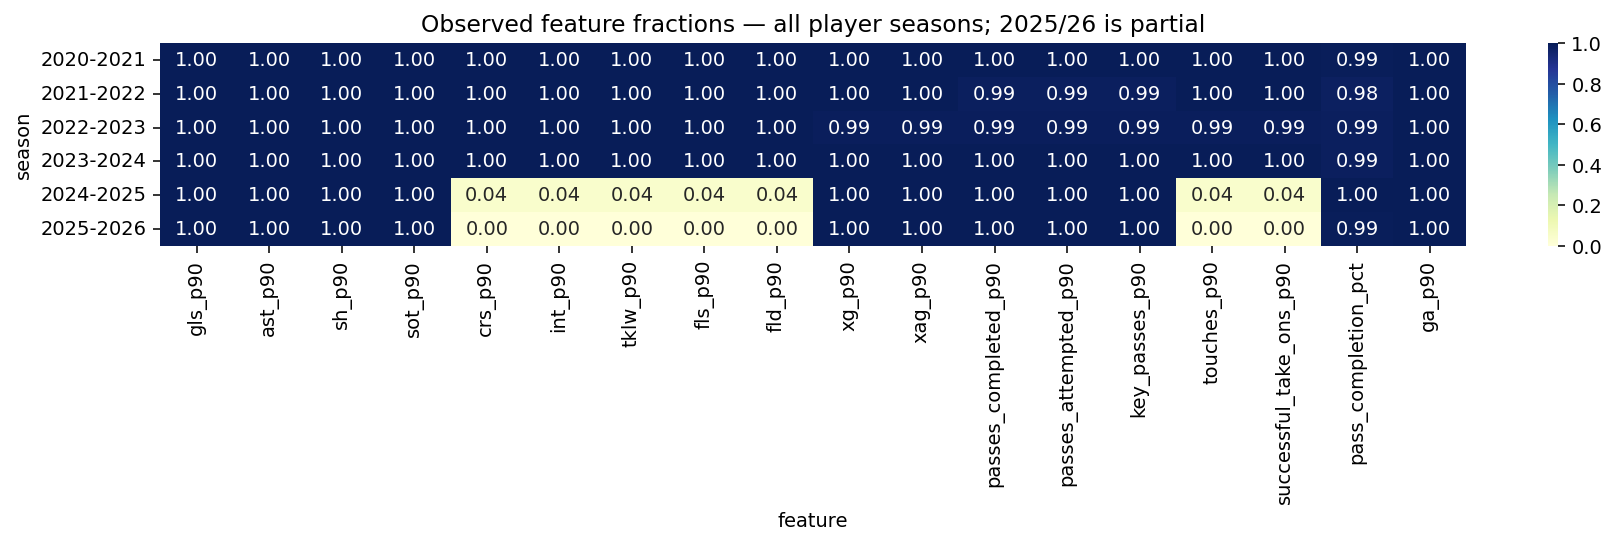

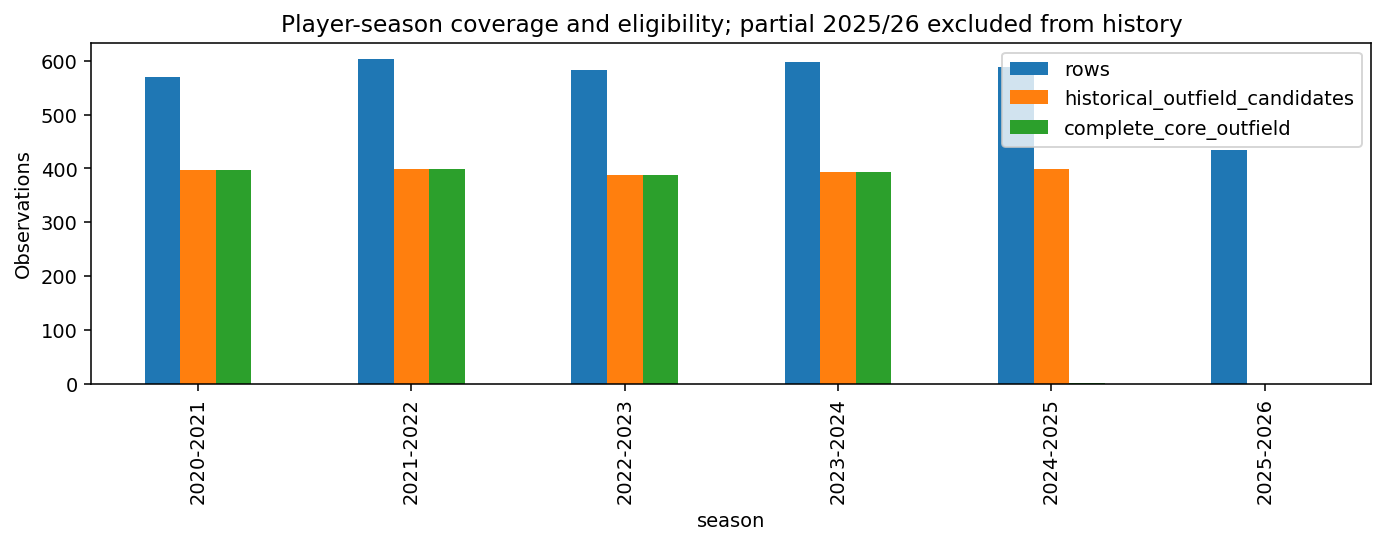

In [3]:
display(pd.read_csv(ROOT/'reports/collected_missingness.csv').query("table == 'collected_player_seasons' and missing > 0") [['field','missing','missing_fraction']])
display(Image(filename=str(ROOT/'reports/collected_feature_availability.png')))
display(Image(filename=str(ROOT/'reports/collected_season_coverage.png')))

## Duplicate handling, transfers between clubs and exposure

Club stints are preserved separately. Player-season rates use summed minutes and compatible totals; they are not averages of stint rates. Aggregation happens before the 450-minute floor, and multi-club records list every club without claiming which was current at a historical decision date. Exact duplicates are removed; conflicting FBref keys fail preprocessing.

In [4]:
display(players.loc[players.club_count.gt(1),['player','season','clubs','minutes','gls','ast','gls_p90']].head(12))
display(pd.DataFrame([manifest['exact_duplicates_removed']]))
display(pd.read_csv(ROOT/'reports/collected_invalid_values.csv').query('invalid_values_nulled > 0'))
display(pd.read_csv(ROOT/'reports/collected_legacy_exclusions.csv'))

,player,season,clubs,minutes,gls,ast,gls_p90
157,Roger Martí,2022-2023,"[""Cádiz"", ""Elche""]",1294.0,1.0,1.0,0.069552
177,Manu Vallejo,2021-2022,"[""Alavés"", ""Valencia""]",468.0,1.0,1.0,0.192308
236,Adrià Pedrosa,2025-2026,"[""Elche"", ""Sevilla""]",93.0,0.0,0.0,0.000000
304,Takefusa Kubo,2020-2021,"[""Getafe"", ""Villarreal""]",1104.0,1.0,1.0,0.081522
341,Joseph Aidoo,2024-2025,"[""Celta Vigo"", ""Valladolid""]",585.0,0.0,0.0,0.000000
354,Óscar Rodríguez Arnaiz,2021-2022,"[""Getafe"", ""Sevilla""]",1360.0,0.0,1.0,0.000000
358,Rubén Sobrino,2020-2021,"[""Cádiz"", ""Valencia""]",1162.0,1.0,0.0,0.077453
359,Rubén Sobrino,2021-2022,"[""Cádiz"", ""Valencia""]",1875.0,4.0,1.0,0.192000
386,Portu,2023-2024,"[""Getafe"", ""Girona""]",1285.0,7.0,5.0,0.490272
508,Ezequiel Ávila,2023-2024,"[""Betis"", ""Osasuna""]",1162.0,2.0,3.0,0.154905


,fbref,transfermarkt_transfers
0,0,1


,table,field,invalid_values_nulled


,source,league,season,rows,use
0,demo,La Liga,2223,180,preserved_only; synthetic excluded and overlap...
1,demo,La Liga,2425,180,preserved_only; synthetic excluded and overlap...
2,demo,Segunda,2223,240,preserved_only; synthetic excluded and overlap...
3,demo,Segunda,2425,240,preserved_only; synthetic excluded and overlap...
4,fbref_cache,La Liga,2324,609,preserved_only; synthetic excluded and overlap...


## Distributions and outliers

Inspect rates after controlling minimum exposure and player role. Extreme observed values are flagged, not clipped. The distributions below use development seasons only. Age is retained where the source provides it, but no missing DOB, height, foot or price is fabricated.

,minutes,age,gls_p90,ast_p90,ga_p90,sh_p90,sot_p90,crs_p90,int_p90,tklw_p90,fls_p90,fld_p90
count,1975.000,1974.000,1975.000,1975.000,1975.000,1975.000,1975.000,1577.000,1577.000,1577.000,1577.000,1577.000
mean,1669.796,26.741,0.122,0.086,0.208,1.188,0.390,1.865,0.878,0.938,1.344,1.251
std,748.610,4.306,0.162,0.098,0.211,0.903,0.375,1.943,0.515,0.479,0.628,0.720
min,451.000,16.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.102,0.000
25%,1044.500,23.000,0.000,0.000,0.052,0.485,0.111,0.267,0.480,0.594,0.888,0.692
50%,1608.000,27.000,0.066,0.060,0.151,0.918,0.265,1.136,0.843,0.886,1.252,1.151
75%,2294.000,30.000,0.173,0.141,0.310,1.750,0.574,3.046,1.229,1.223,1.689,1.678
max,3407.000,41.000,1.149,0.830,1.354,5.686,2.531,10.299,3.002,3.411,4.527,4.062


,source_player_id,player,season,minutes,gls_p90,sh_p90,quality_outlier,quality_inconsistent_counts,historical_candidate
0,375ed9d7,Milutin Osmajić,2023-2024,5.0,0.000000,36.000000,True,False,False
1,37f1cf47,Ander Capa,2021-2022,4.0,0.000000,22.500000,True,False,False
2,50cbc806,Iker Benito,2025-2026,27.0,3.333333,3.333333,True,False,False
3,8d78e732,Robert Lewandowski,2025-2026,51.0,3.529412,3.529412,True,False,False
4,a2d9cf74,Pascu,2022-2023,10.0,9.000000,9.000000,True,False,False


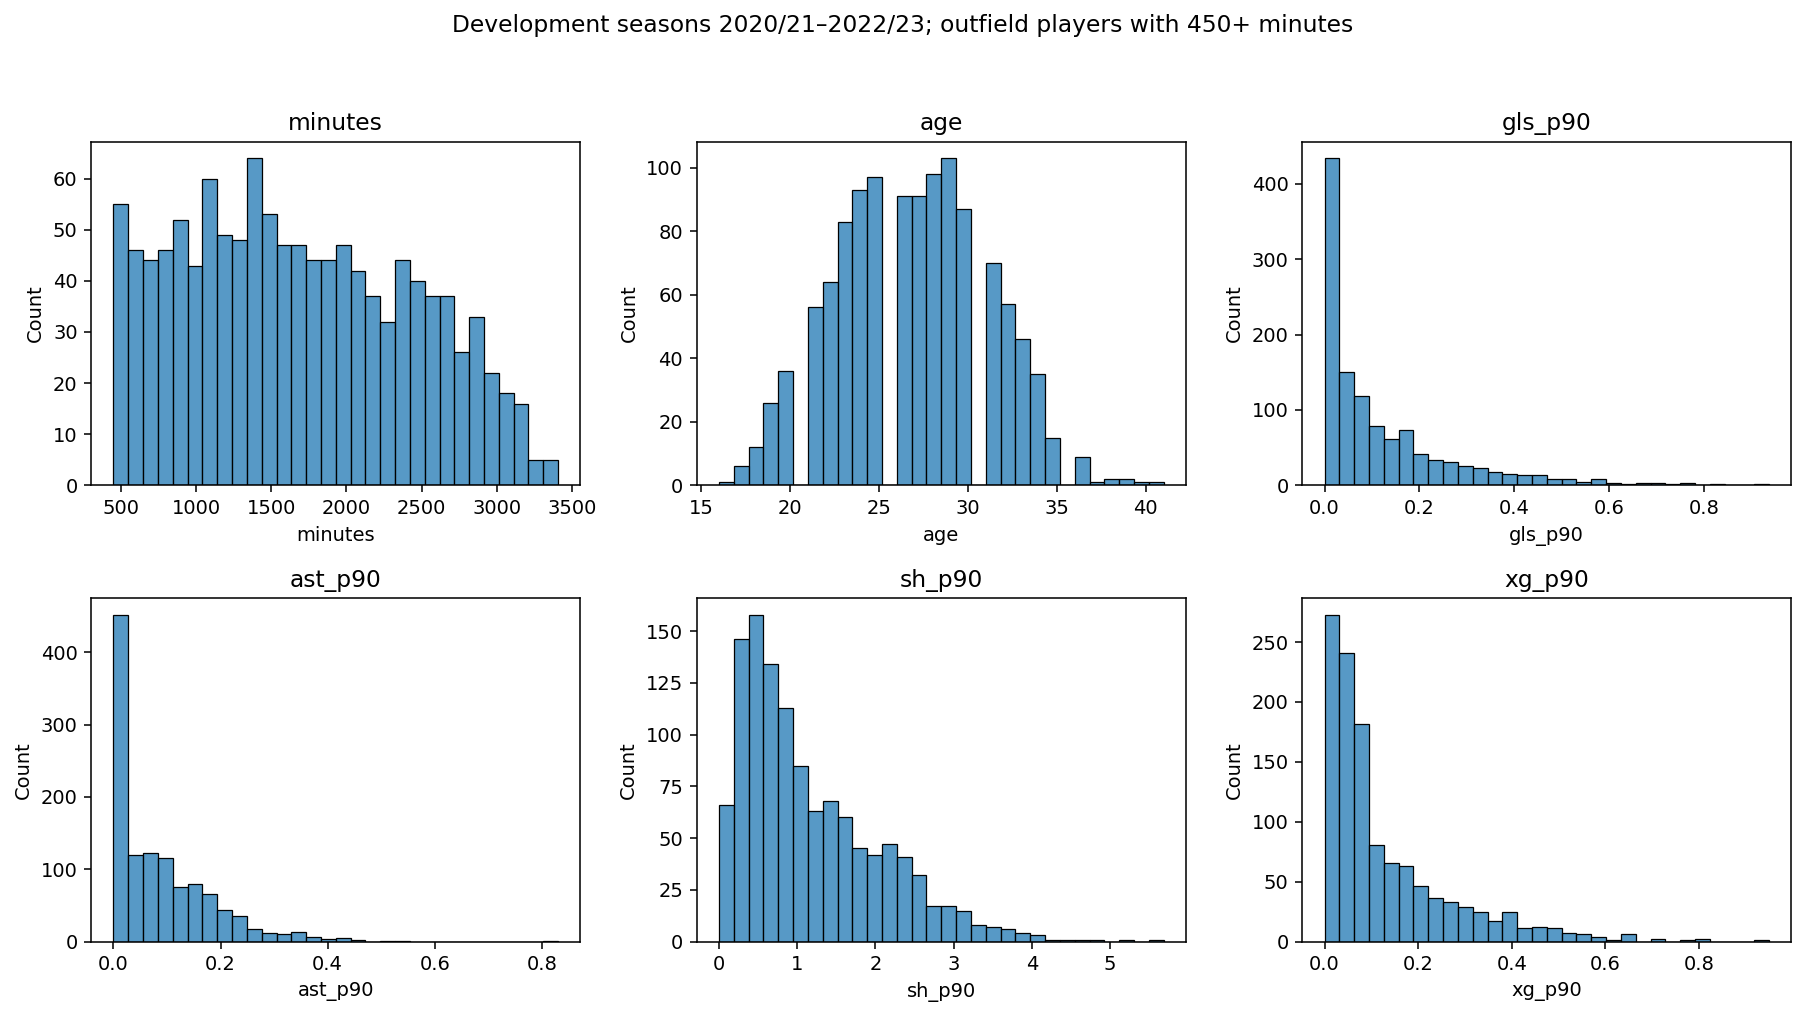

**Finding:** 5 player-season records carry review flags; 0 enter the historical baseline candidate set. 3 ages remain unknown.

In [5]:
display(eligible[['minutes','age']+FEATURE_COLS].describe().round(3))
display(pd.read_csv(ROOT/'reports/collected_outliers.csv'))
display(Image(filename=str(ROOT/'reports/collected_distributions.png')))
display(Markdown(f"**Finding:** {summary['outlier_flags']} player-season records carry review flags; {summary['outliers_in_historical_candidates']} enter the historical baseline candidate set. {summary['missing_ages']} ages remain unknown."))

## Correlations and redundant features

Spearman correlations use the shared 2020/21–2021/22 development period only, excluding both designs’ validation and holdout seasons. G+A is excluded because it is exactly goals plus assists; retaining it in a similarity feature vector would overweight attack output. Missing xA is excluded rather than substituted with xAG. Correlations are descriptive and do not establish causality or a validated feature-selection rule.

,gls_p90,ast_p90,sh_p90,sot_p90,crs_p90,int_p90,tklw_p90,fls_p90,fld_p90,xg_p90,xag_p90,passes_completed_p90,passes_attempted_p90,key_passes_p90,touches_p90,successful_take_ons_p90,pass_completion_pct
gls_p90,1.00,0.33,0.68,0.77,0.09,-0.54,-0.37,0.00,0.32,0.77,0.40,-0.33,-0.34,0.37,-0.33,0.30,-0.23
ast_p90,0.33,1.00,0.39,0.39,0.45,-0.32,-0.05,-0.08,0.28,0.37,0.72,-0.03,0.01,0.63,0.02,0.44,-0.17
sh_p90,0.68,0.39,1.00,0.90,0.24,-0.61,-0.32,0.13,0.48,0.87,0.54,-0.44,-0.43,0.52,-0.40,0.50,-0.37
sot_p90,0.77,0.39,0.90,1.00,0.21,-0.60,-0.35,0.08,0.42,0.85,0.51,-0.41,-0.41,0.49,-0.38,0.46,-0.33
crs_p90,0.09,0.45,0.24,0.21,1.00,-0.18,0.18,-0.04,0.32,0.12,0.63,-0.01,0.11,0.71,0.12,0.52,-0.42
int_p90,-0.54,-0.32,-0.61,-0.60,-0.18,1.00,0.43,-0.01,-0.33,-0.63,-0.41,0.42,0.43,-0.40,0.44,-0.37,0.31
tklw_p90,-0.37,-0.05,-0.32,-0.35,0.18,0.43,1.00,0.29,0.03,-0.42,-0.06,0.32,0.35,0.02,0.39,0.06,0.13
fls_p90,0.00,-0.08,0.13,0.08,-0.04,-0.01,0.29,1.00,0.31,0.07,-0.03,-0.16,-0.15,0.00,-0.11,0.13,-0.15
fld_p90,0.32,0.28,0.48,0.42,0.32,-0.33,0.03,0.31,1.00,0.39,0.42,-0.23,-0.20,0.45,-0.16,0.55,-0.27
xg_p90,0.77,0.37,0.87,0.85,0.12,-0.63,-0.42,0.07,0.39,1.00,0.48,-0.46,-0.46,0.43,-0.44,0.40,-0.33


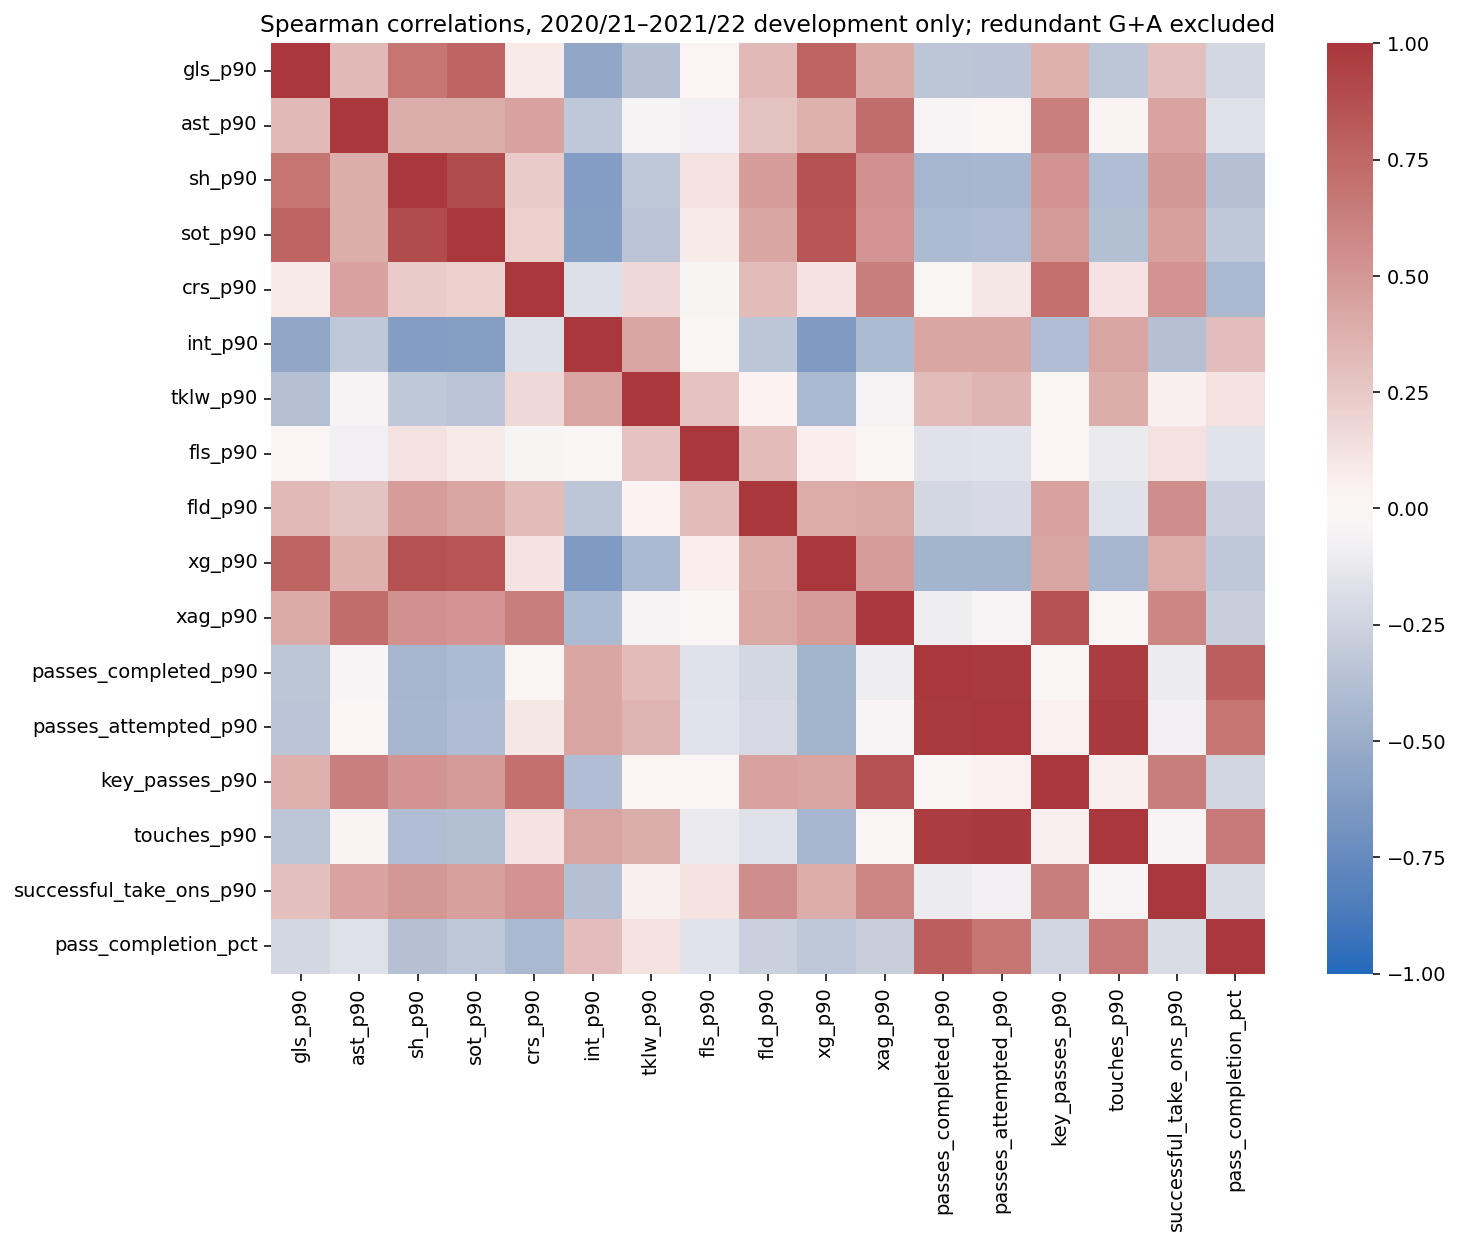

In [6]:
display(pd.read_csv(ROOT/'reports/collected_training_correlations.csv',index_col=0).round(2))
display(Image(filename=str(ROOT/'reports/collected_training_correlations.png')))

## Position, season and league comparisons

Outfield comparisons separate DF/MF/FW. Goalkeepers remain in the inventory but require goalkeeper-specific metrics before goalkeeper recommendations are meaningful. Sparse 2024/25 defensive coverage makes those medians unrepresentative; inspect observed counts beside each estimate. A real La Liga–Segunda comparison is unavailable; synthetic Segunda rows are excluded.

,season,pos_main,rows,median_minutes,median_goals_p90,median_assists_p90,median_shots_p90,median_interceptions_p90,interceptions_observed
0,2020-2021,DF,158,1782.5,0.000000,0.000000,0.427791,1.334458,158
1,2020-2021,FW,91,1438.0,0.258176,0.111940,1.965423,0.337553,91
2,2020-2021,MF,147,1549.0,0.075949,0.048570,1.046512,1.009975,147
3,2021-2022,DF,153,1734.0,0.000000,0.000000,0.503262,1.152709,153
4,2021-2022,FW,100,1497.5,0.253641,0.114690,2.279975,0.305950,100
5,2021-2022,MF,146,1423.5,0.066227,0.071472,1.094401,0.916524,146
6,2022-2023,DF,157,1713.0,0.000000,0.000000,0.493421,0.926910,157
7,2022-2023,FW,97,1449.0,0.292208,0.094142,2.394495,0.271084,97
8,2022-2023,MF,134,1645.0,0.071828,0.090817,1.027262,0.850706,134
9,2023-2024,DF,162,1702.5,0.000000,0.036213,0.499161,0.926926,162


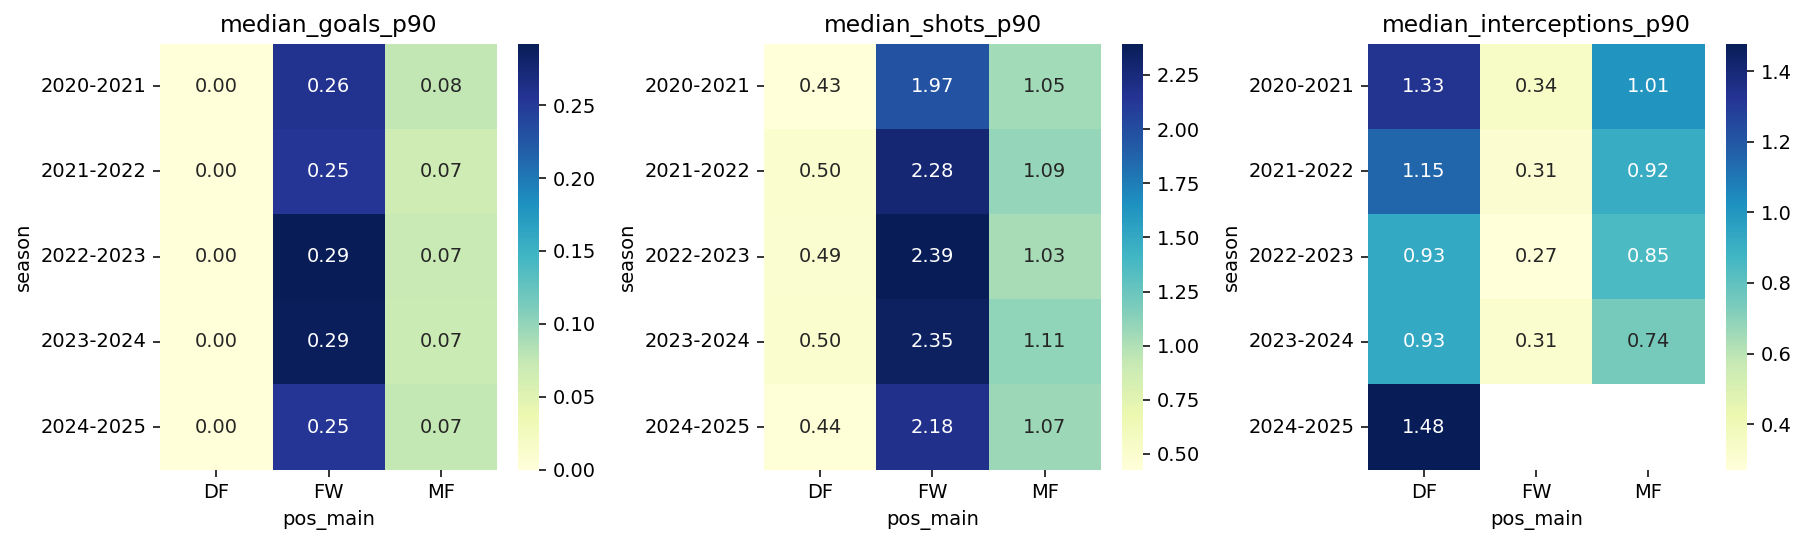

rows  rows_above_60pct
season    style                                    
2020-2021 contraataque        570               570
          creator             570               570
          desborde_banda      570               570
          finisher            570               570
          posesion            570               570
          presion_alta        570               570
          solidez_defensiva   570               570
          vertical            570               570
2021-2022 contraataque        603               603
          creator             603               603
          desborde_banda      603               603
          finisher            603               603
          posesion            603               603
          presion_alta        603               603
          solidez_defensiva   603               603
          vertical            603               603
2022-2023 contraataque        583               583
          creator             583               583
          desborde_banda      583               583
          finisher            583               583
          posesion            583               583
          presion_alta        583               583
          solidez_defensiva   583               583
          vertical            583               583
2023-2024 contraataque        598               598
          creator             598               598
          desborde_banda      598               598
          finisher            598               598
          posesion            598               598
          presion_alta        598               598
          solidez_defensiva   598               598
          vertical            598               598
2024-2025 contraataque        589               589
          creator             589               589
          desborde_banda      589               589
          finisher            589               589
          posesion            589               589
          presion_alta        589                25
          solidez_defensiva   589                25
          vertical            589               589
2025-2026 contraataque        435               435
          creator             435               435
          desborde_banda      435               435
          finisher            435               435
          posesion            435               435
          presion_alta        435                 0
          solidez_defensiva   435                 0
          vertical            435               435

Broad styles remain **statistical proxies**, even when their configured weights have adequate coverage. Direct pressing, transitions and goalkeeper metrics have not been collected.

In [7]:
display(pd.read_csv(ROOT/'reports/collected_position_comparisons.csv'))
display(Image(filename=str(ROOT/'reports/collected_position_comparisons.png')))
styles=pd.read_csv(ROOT/'reports/collected_style_coverage.csv')
display(styles.groupby(['season','style'])[['rows','rows_above_60pct']].sum())
display(Markdown('Broad styles remain **statistical proxies**, even when their configured weights have adequate coverage. Direct pressing, transitions and goalkeeper metrics have not been collected.'))

## Understat shot-event cleaning

The archive changes from h_a to home_away for the shot side; the cleaner reconciles both and validates the values before assigning a club. Own goals are retained separately and excluded from attacking shots, goals and xG. Match counts here mean matches with recorded events, not player appearances. Unknown minutes prevent per-90 rates. Provider timestamps have unspecified timezone; they are not silently labelled UTC.

In [8]:
display(pd.read_csv(ROOT/'reports/collected_understat_coverage.csv'))
display(tables['collected_understat_shooters'].head())
display(Markdown(f"**Finding:** {summary['understat_shot_records']:,} event records contain {summary['understat_attacking_shots']:,} attacking shots and {summary['understat_own_goals']} own-goal events."))

,season,recorded_events,attacking_shots,own_goals,matches,first_date,last_date
0,2020-2021,8132,8101,31,380,2020-09-12 14:00:00,2021-05-23 19:00:00
1,2021-2022,8977,8952,25,380,2021-08-13 19:00:00,2022-05-22 20:00:00
2,2022-2023,9374,9341,33,380,2022-08-12 19:00:00,2023-06-04 18:00:00
3,2023-2024,9311,9283,28,380,2023-08-11 17:30:00,2024-05-26 19:00:00
4,2024-2025,9056,9029,27,380,2024-08-15 17:00:00,2025-05-25 19:00:00
5,2025-2026,997,993,4,41,2025-08-15 17:00:00,2025-09-15 19:00:00


,source_player_id,season,team,player,recorded_shot_events,shots,goals,own_goals,xg,matches_with_shot_records,first_match,last_match,league,source,minutes,coverage_note,partial_season
0,10014,2021-2022,Real Sociedad,Cristo Romero,1,1,0,0,0.011577,1,2021-09-26 16:30:00,2021-09-26 16:30:00,La Liga,understat,NaN,"shooters only; no exposure, assists or xA; sou...",False
1,10024,2021-2022,Valencia,Cristhian Mosquera,1,1,0,0,0.477988,1,2022-03-05 17:30:00,2022-03-05 17:30:00,La Liga,understat,NaN,"shooters only; no exposure, assists or xA; sou...",False
2,10024,2022-2023,Valencia,Cristhian Mosquera,2,2,0,0,0.121479,2,2022-08-14 17:30:00,2023-01-29 13:00:00,La Liga,understat,NaN,"shooters only; no exposure, assists or xA; sou...",False
3,10024,2023-2024,Valencia,Cristhian Mosquera,9,9,0,0,0.996248,9,2023-09-16 14:15:00,2024-03-30 17:30:00,La Liga,understat,NaN,"shooters only; no exposure, assists or xA; sou...",False
4,10024,2024-2025,Valencia,Cristhian Mosquera,5,5,1,0,0.351448,5,2024-09-21 16:30:00,2025-04-19 12:00:00,La Liga,understat,NaN,"shooters only; no exposure, assists or xA; sou...",False


**Finding:** 45,847 event records contain 45,699 attacking shots and 148 own-goal events.

## Retained Transfermarkt context and identity review

DOB and height units are normalized for auditing, but profile attributes have no verified historical as-of date. Values remain separate from fees; missing values/fees are not zero, and an upstream zero fee is not automatically a verified free transfer. Arrival/departure records are retained as source records and grouped into potential movements without claiming uniquely dated transfers. Source-use flags remain attached. No new data are collected and these records do not enter a fitted model.

In [9]:
display(pd.DataFrame([{k:summary[k] for k in ['transfermarkt_profiles','missing_market_values','parsed_dobs','parsed_heights','transfer_records','potential_movement_groups','unverified_zero_fees','missing_fees','eligible_historical_budget_records','segunda_scorer_sample_rows']}]))
queue=tables['identity_candidates']
display(queue.groupby(['right_source','status']).size().rename('pairs').reset_index())
display(queue.groupby('right_source').ambiguous.sum().rename('ambiguous_pairs').reset_index())
display(Markdown(f"**Finding:** {summary['candidate_identity_pairs']:,} identity proposals; {summary['reviewed_identity_pairs']} approved pairs. Name/club/season corroboration does not automatically join sources. {summary['identity_birth_year_conflicts']} upstream mappings conflict with reported birth years."))
display(tables['collected_segunda_scorer_sample'][['player','team','season','minutes','gls','ast','observation_scope']].head())
display(Markdown('The 25-row Segunda scorer sample is retained separately; it is biased toward goalscorers and does not support a full-league comparison or historical model cohort.'))

,transfermarkt_profiles,missing_market_values,parsed_dobs,parsed_heights,transfer_records,potential_movement_groups,unverified_zero_fees,missing_fees,eligible_historical_budget_records,segunda_scorer_sample_rows
0,2018,93,2016,1954,1933,1882,351,1239,0,25


,right_source,status,pairs
0,transfermarkt,conflicting_birth_year,3
1,transfermarkt,review_required,1377
2,understat,review_required,991


,right_source,ambiguous_pairs
0,transfermarkt,25
1,understat,42


**Finding:** 2,371 identity proposals; 0 approved pairs. Name/club/season corroboration does not automatically join sources. 3 upstream mappings conflict with reported birth years.

,player,team,season,minutes,gls,ast,observation_scope
0,Luis Suárez,UD Almería,2024-2025,3648,27,8,first-page goalscorer league-season totals; re...
1,Joaquín Panichelli,CD Mirandés,2024-2025,3463,20,4,first-page goalscorer league-season totals; re...
2,Andrés Martín,Racing Santander,2024-2025,3354,16,17,first-page goalscorer league-season totals; re...
3,Yeremay Hernández,Deportivo de La Coruña,2024-2025,3053,15,5,first-page goalscorer league-season totals; re...
4,Alemão,Real Oviedo,2024-2025,2987,14,4,first-page goalscorer league-season totals; re...


The 25-row Segunda scorer sample is retained separately; it is biased toward goalscorers and does not support a full-league comparison or historical model cohort.

## Preprocessing decisions and next experiments

The offensive baseline uses train=2020/21–2022/23, validation=2023/24 and holdout=2024/25. The full-core proxy uses train=2020/21–2021/22, validation=2022/23 and holdout=2023/24, with 2024/25 only sparse monitoring. Both keep partial 2025/26 as monitoring. These distinct designs accommodate the missing 2024/25 defensive coverage. These season splits prevent directly pooling future seasons into development, but archive publication timestamps are insufficient for strict historical as-of validation. Fit imputation/scaling/PCA/K-means only inside a later training experiment. Do not use 2024/25 outcomes to tune features or weights. Offensive comparisons can use consistently observed fields; the full ten-feature tactical proxy has almost no eligible 2024/25 coverage. Budget and actual-transfer success validation remain unsupported.

In [10]:
display(pd.DataFrame([summary]))
display(Markdown(f"**Prepared:** {summary['historical_baseline_candidates']:,} historical baseline candidates and {summary['historical_complete_core_candidates']:,} fully measured core-proxy candidates. This notebook reports preprocessing and EDA, **not model evaluation results**."))

,dataset_version,player_club_rows,player_season_rows,fbref_unique_players,historical_baseline_candidates,historical_complete_core_candidates,development_candidates,core_proxy_development_candidates,multi_club_seasons,missing_ages,...,reviewed_identity_pairs,candidate_identity_pairs,identity_birth_year_conflicts,identity_ambiguous_pairs,eligible_historical_budget_records,raw_data_modified,model_trained,imputation_or_scaling_fitted,league_comparison,pressure_or_goalkeeper_metrics
0,42a86ea4014765ff4015fca36ab1bd3cb778501edd6e9e...,3443,3378,1451,1975,1577,1183,795,65,3,...,0,2371,3,67,0,False,False,False,Unavailable: no complete real Segunda performa...,Not collected; broad tactical labels remain pr...


**Prepared:** 1,975 historical baseline candidates and 1,577 fully measured core-proxy candidates. This notebook reports preprocessing and EDA, **not model evaluation results**.